In [1]:
import torch
from torch.autograd import grad
import torch.nn as nn
from numpy import genfromtxt
import torch.optim as optim
import matplotlib.pyplot as plt
import torch.nn.functional as F

dengue_data = genfromtxt('./data/sanjuan_train.csv', delimiter=',') #in the form of [t, Itot]

torch.manual_seed(1234)

In [2]:
#%%time

PATH = 'dengue' 

class DINN(nn.Module):
    def __init__(self, t, Itot_data):
        super(DINN, self).__init__()
        self.t = torch.tensor(t, requires_grad=True)
        self.t_float = self.t.float()
        self.t_batch = torch.reshape(self.t_float, (len(self.t),1)) #reshape for batch 
        
        # Only Itot has actual data
        self.Itot = torch.tensor(Itot_data)

        self.losses = [] #keep the losses
        self.save = 2 #which file to save to

        #learnable parameters
        self.lambda_tilda = torch.nn.Parameter(torch.rand(1, requires_grad=True))
        self.beta_m_tilda = torch.nn.Parameter(torch.rand(1, requires_grad=True))
        self.mu_m_tilda = torch.nn.Parameter(torch.rand(1, requires_grad=True))
        self.theta_m_tilda = torch.nn.Parameter(torch.rand(1, requires_grad=True))
        self.mu_h_tilda = torch.nn.Parameter(torch.rand(1, requires_grad=True))
        self.beta_h_tilda = torch.nn.Parameter(torch.rand(1, requires_grad=True))
        self.theta_h_tilda = torch.nn.Parameter(torch.rand(1, requires_grad=True))
        self.gamma_h_tilda = torch.nn.Parameter(torch.rand(1, requires_grad=True))


        #matrices (x8 for Hr, Hs, He, Hi, Me, Ms, Mi, Itot) for the gradients
        self.m1 = torch.zeros((len(self.t), 8)); self.m1[:, 0] = 1
        self.m2 = torch.zeros((len(self.t), 8)); self.m2[:, 1] = 1
        self.m3 = torch.zeros((len(self.t), 8)); self.m3[:, 2] = 1
        self.m4 = torch.zeros((len(self.t), 8)); self.m4[:, 3] = 1
        self.m5 = torch.zeros((len(self.t), 8)); self.m5[:, 4] = 1
        self.m6 = torch.zeros((len(self.t), 8)); self.m6[:, 5] = 1
        self.m7 = torch.zeros((len(self.t), 8)); self.m7[:, 6] = 1
        self.m8 = torch.zeros((len(self.t), 8)); self.m8[:, 7] = 1

        # Using log1p/expm1 normalization for all compartments
        # log1p(x) = log(1 + x) is numerically stable for small x
        # expm1(x) = exp(x) - 1 is the inverse
        # This works better for exponential growth in epidemic models
        
        # Only Itot has actual data
        self.Itot_hat = torch.log1p(self.Itot)  # log(1 + Itot) 

        #NN
        self.net_dengue = self.Net_dengue()
        self.params = list(self.net_dengue.parameters())
        self.params.extend(list([self.lambda_tilda, self.beta_m_tilda, self.mu_m_tilda, self.theta_m_tilda, self.mu_h_tilda, self.beta_h_tilda, self.theta_h_tilda, self.gamma_h_tilda]))

        
    #force parameters to be in a range
    @property
    def lambda_(self):
        return torch.tanh(self.lambda_tilda) * 0.3 + 30
    @property 
    def beta_m(self):
        return torch.tanh(self.beta_m_tilda) * 0.001 + 0.05
    @property
    def mu_m(self):
        return torch.tanh(self.mu_m_tilda) * 0.001 + 0.016
    @property
    def theta_m(self):
        return torch.tanh(self.theta_m_tilda) * 0.01 + 0.2
    @property
    def mu_h(self):
        return torch.tanh(self.mu_h_tilda) * 0.001 + 0.0195
    @property
    def beta_h(self):
        return torch.tanh(self.beta_h_tilda) * 0.001 + 0.055
    @property
    def theta_h(self):
        return torch.tanh(self.theta_h_tilda) * 0.01 + 0.53
    @property
    def gamma_h(self):
        return torch.tanh(self.gamma_h_tilda) * 0.05 + 0.1


    #nets
    class Net_dengue(nn.Module): # input = [t]
        def __init__(self):
            super(DINN.Net_dengue, self).__init__()
            self.fc1=nn.Linear(1, 20) #takes 100 t's
            self.fc2=nn.Linear(20, 20)
            self.fc3=nn.Linear(20, 20)
            self.fc4=nn.Linear(20, 20)
            self.fc5=nn.Linear(20, 20)
            self.fc6=nn.Linear(20, 20)
            self.fc7=nn.Linear(20, 20)
            self.fc8=nn.Linear(20, 20)
            self.out=nn.Linear(20, 8) #outputs Hr, Hs, He, Hi, Me, Ms, Mi, Itot

        def forward(self, t):
            dengue=F.gelu(self.fc1(t))
            dengue=F.gelu(self.fc2(dengue))
            dengue=F.gelu(self.fc3(dengue))
            dengue=F.gelu(self.fc4(dengue))
            dengue=F.gelu(self.fc5(dengue))
            dengue=F.gelu(self.fc6(dengue))
            dengue=F.gelu(self.fc7(dengue))
            dengue=F.gelu(self.fc8(dengue))
            # Apply softplus to ensure non-negative outputs (since log1p outputs are non-negative)
            dengue=F.softplus(self.out(dengue))
            return dengue    

    def net_f(self, t_batch):       

        dengue_hat = self.net_dengue(t_batch)

        Hr_hat, Hs_hat, He_hat, Hi_hat, Me_hat, Ms_hat, Mi_hat, Itot_hat = dengue_hat[:,0], dengue_hat[:,1], dengue_hat[:,2], dengue_hat[:,3], dengue_hat[:,4], dengue_hat[:,5], dengue_hat[:,6], dengue_hat[:,7]

        #Hr_hat
        dengue_hat.backward(self.m1, retain_graph = True)
        Hr_hat_t = self.t.grad.clone()
        self.t.grad.zero_()

        #Hs_hat
        dengue_hat.backward(self.m2, retain_graph = True)
        Hs_hat_t = self.t.grad.clone()
        self.t.grad.zero_()

        #He_hat
        dengue_hat.backward(self.m3, retain_graph = True)
        He_hat_t = self.t.grad.clone()
        self.t.grad.zero_()

        #Hi_hat
        dengue_hat.backward(self.m4, retain_graph = True)
        Hi_hat_t = self.t.grad.clone()
        self.t.grad.zero_()

        #Me_hat
        dengue_hat.backward(self.m5, retain_graph = True)
        Me_hat_t = self.t.grad.clone()
        self.t.grad.zero_()

        #Ms_hat
        dengue_hat.backward(self.m6, retain_graph = True)
        Ms_hat_t = self.t.grad.clone()
        self.t.grad.zero_()

        #Mi_hat
        dengue_hat.backward(self.m7, retain_graph = True)
        Mi_hat_t = self.t.grad.clone()
        self.t.grad.zero_()

        #Itot_hat
        dengue_hat.backward(self.m8, retain_graph = True)
        Itot_hat_t = self.t.grad.clone()
        self.t.grad.zero_()


        # Unnormalize all compartments using expm1 (inverse of log1p)
        Hr = torch.expm1(Hr_hat)  # exp(Hr_hat) - 1
        Hs = torch.expm1(Hs_hat)
        He = torch.expm1(He_hat)
        Hi = torch.expm1(Hi_hat)
        Me = torch.expm1(Me_hat)
        Ms = torch.expm1(Ms_hat)
        Mi = torch.expm1(Mi_hat)
        Itot = torch.expm1(Itot_hat)

        # Calculate total populations
        H = torch.clamp(Hr + Hs + He + Hi, min=1e-8)
        M = torch.clamp(Me + Ms + Mi, min=1e-8)

        # ODE equations with log normalization
        # For log normalization: d(log(1+x))/dt = 1/(1+x) * dx/dt
        f1_hat = Hr_hat_t - (self.gamma_h * Hi - self.mu_h * Hr) / (1.0 + Hr)
        f2_hat = Hs_hat_t - (self.mu_h * H - self.beta_h * Mi * Hs / M - self.mu_h * Hs) / (1.0 + Hs)
        f3_hat = He_hat_t - (self.beta_h * Mi * Hs / M - (self.theta_h + self.mu_h) * He) / (1.0 + He)
        f4_hat = Hi_hat_t - (self.theta_h * He - (self.gamma_h + self.mu_h) * Hi) / (1.0 + Hi)
        f5_hat = Me_hat_t - (self.beta_m * Hi * Ms / H - (self.theta_m + self.mu_m) * Me) / (1.0 + Me)
        f6_hat = Ms_hat_t - (self.lambda_ - self.beta_m * Hi * Ms / H - self.mu_m * Ms) / (1.0 + Ms)
        f7_hat = Mi_hat_t - (self.theta_m * Me - self.mu_m * Mi) / (1.0 + Mi)
        f8_hat = Itot_hat_t - (self.theta_h * He) / (1.0 + Itot) 

        return f1_hat, f2_hat, f3_hat, f4_hat, f5_hat, f6_hat, f7_hat, f8_hat, Hr_hat, Hs_hat, He_hat, Hi_hat, Me_hat, Ms_hat, Mi_hat, Itot_hat
    
    def load(self):
      # Load checkpoint
      try:
        checkpoint = torch.load(PATH + str(self.save)+'.pt') 
        print('\nloading pre-trained model...')
        self.load_state_dict(checkpoint['model'])
        self.optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
        self.scheduler.load_state_dict(checkpoint['scheduler'])
        epoch = checkpoint['epoch']
        loss = checkpoint['loss']
        self.losses = checkpoint['losses']
        print('loaded previous loss: ', loss)
      except RuntimeError :
          print('changed the architecture, ignore')
          pass
      except FileNotFoundError:
          pass

    def train(self, n_epochs):
      #try loading
      self.load()

      #train
      print('\nstarting training...\n')
      
      for epoch in range(n_epochs):
        #lists to hold the output (maintain only the final epoch)
        Hr_pred_list = []
        Hs_pred_list = []
        He_pred_list = []
        Hi_pred_list = []
        Me_pred_list = []
        Ms_pred_list = []
        Mi_pred_list = []
        Itot_pred_list = []

        f1_hat, f2_hat, f3_hat, f4_hat, f5_hat, f6_hat, f7_hat, f8_hat, Hr_hat_pred, Hs_hat_pred, He_hat_pred, Hi_hat_pred, Me_hat_pred, Ms_hat_pred, Mi_hat_pred, Itot_hat_pred = self.net_f(self.t_batch)
        self.optimizer.zero_grad()

        # Unnormalize predictions from log space using expm1
        Hr_pred_list.append(torch.expm1(Hr_hat_pred))
        Hs_pred_list.append(torch.expm1(Hs_hat_pred))
        He_pred_list.append(torch.expm1(He_hat_pred))
        Hi_pred_list.append(torch.expm1(Hi_hat_pred))
        Me_pred_list.append(torch.expm1(Me_hat_pred))
        Ms_pred_list.append(torch.expm1(Ms_hat_pred))
        Mi_pred_list.append(torch.expm1(Mi_hat_pred))
        Itot_pred_list.append(torch.expm1(Itot_hat_pred))

        # Separate data loss and physics loss
        loss_data = torch.mean(torch.square(self.Itot_hat - Itot_hat_pred))  # Data fitting for Itot only
        
        loss_physics = (torch.mean(torch.square(f1_hat)) + torch.mean(torch.square(f2_hat)) +  # Physics constraints
                       torch.mean(torch.square(f3_hat)) + torch.mean(torch.square(f4_hat)) +
                       torch.mean(torch.square(f5_hat)) + torch.mean(torch.square(f6_hat)) +
                       torch.mean(torch.square(f7_hat)) + torch.mean(torch.square(f8_hat)))
        
        # Combined loss
        loss = loss_data + loss_physics

        loss.backward()

        self.optimizer.step()
        self.scheduler.step(loss.detach())  # Detach to avoid warning

        self.losses.append(loss.item())

        if epoch % 100 == 0:
          # Get current learning rate
          current_lr = self.optimizer.param_groups[0]['lr']
          print(f'\nEpoch {epoch}, Total Loss: {loss.item():.6f}, Data Loss: {loss_data.item():.6f}, Physics Loss: {loss_physics.item():.6f}')
          print(f'  Learning Rate: {current_lr:.2e}')

        # #loss + model parameters update
        # if epoch % 4000 == 999:
        #   #checkpoint save
        #   print('\nSaving model... Loss is: ', loss)
        #   torch.save({
        #       'epoch': epoch,
        #       'model': self.state_dict(),
        #       'optimizer_state_dict': self.optimizer.state_dict(),
        #       'scheduler': self.scheduler.state_dict(),
        #       'loss': loss,
        #       'losses': self.losses,
        #       }, PATH + str(self.save)+'.pt')
        #   if self.save % 2 > 0: #its on 3
        #     self.save = 2 #change to 2
        #   else: #its on 2
        #     self.save = 3 #change to 3

        #   print('epoch: ', epoch)
        #   print('#################################')
        
      #plot
      plt.plot(self.losses, color = 'teal')
      plt.xlabel('Epochs')
      plt.ylabel('Loss')
      return Hr_pred_list, Hs_pred_list, He_pred_list, Hi_pred_list, Me_pred_list, Ms_pred_list, Mi_pred_list, Itot_pred_list


starting training...


Epoch 0, Total Loss: 237.686263, Data Loss: 33.563302, Physics Loss: 204.122961
  Learning Rate: 5.00e-04

Epoch 100, Total Loss: 18.775493, Data Loss: 7.972312, Physics Loss: 10.803181
  Learning Rate: 5.00e-04

Epoch 200, Total Loss: 4.955035, Data Loss: 2.879039, Physics Loss: 2.075996
  Learning Rate: 5.00e-04

Epoch 300, Total Loss: 3.085551, Data Loss: 2.617292, Physics Loss: 0.468259
  Learning Rate: 5.00e-04

Epoch 400, Total Loss: 2.534700, Data Loss: 2.288677, Physics Loss: 0.246022
  Learning Rate: 5.00e-04

Epoch 500, Total Loss: 2.043608, Data Loss: 1.860330, Physics Loss: 0.183278
  Learning Rate: 5.00e-04

Epoch 600, Total Loss: 1.671719, Data Loss: 1.530219, Physics Loss: 0.141500
  Learning Rate: 5.00e-04

Epoch 700, Total Loss: 1.263234, Data Loss: 1.156430, Physics Loss: 0.106804
  Learning Rate: 5.00e-04

Epoch 800, Total Loss: 0.833317, Data Loss: 0.757334, Physics Loss: 0.075983
  Learning Rate: 5.00e-04

Epoch 900, Total Loss: 0.405447, Da

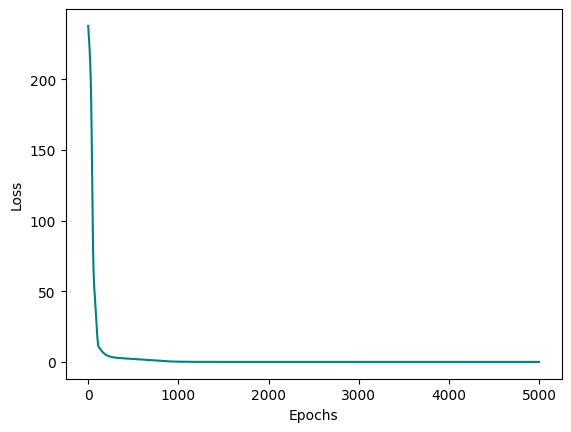

In [3]:
#%%time

dinn = DINN(dengue_data[0], dengue_data[1]) 

# More conservative optimizer settings for stable training
learning_rate = 5e-4  # Lower learning rate
optimizer = optim.Adam(dinn.params, lr=learning_rate, betas=(0.9, 0.999), weight_decay=1e-5)  # Add weight decay
dinn.optimizer = optimizer

# Gentler learning rate decay with longer patience
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    dinn.optimizer, 
    mode='min', 
    factor=0.7,  # Less aggressive reduction (was 0.5)
    patience=3000,  # Wait longer before reducing (was 2000)
    min_lr=1e-7,
)

dinn.scheduler = scheduler

try: 
  Hr_pred_list, Hs_pred_list, He_pred_list, Hi_pred_list, Me_pred_list, Ms_pred_list, Mi_pred_list, Itot_pred_list = dinn.train(5000) #train for 10000 epochs
except EOFError:
  if dinn.save == 2:
    dinn.save = 3
    Hr_pred_list, Hs_pred_list, He_pred_list, Hi_pred_list, Me_pred_list, Ms_pred_list, Mi_pred_list, Itot_pred_list = dinn.train(5000) #train
  elif dinn.save == 3:
    dinn.save = 2
    Hr_pred_list, Hs_pred_list, He_pred_list, Hi_pred_list, Me_pred_list, Ms_pred_list, Mi_pred_list, Itot_pred_list = dinn.train(5000) #train

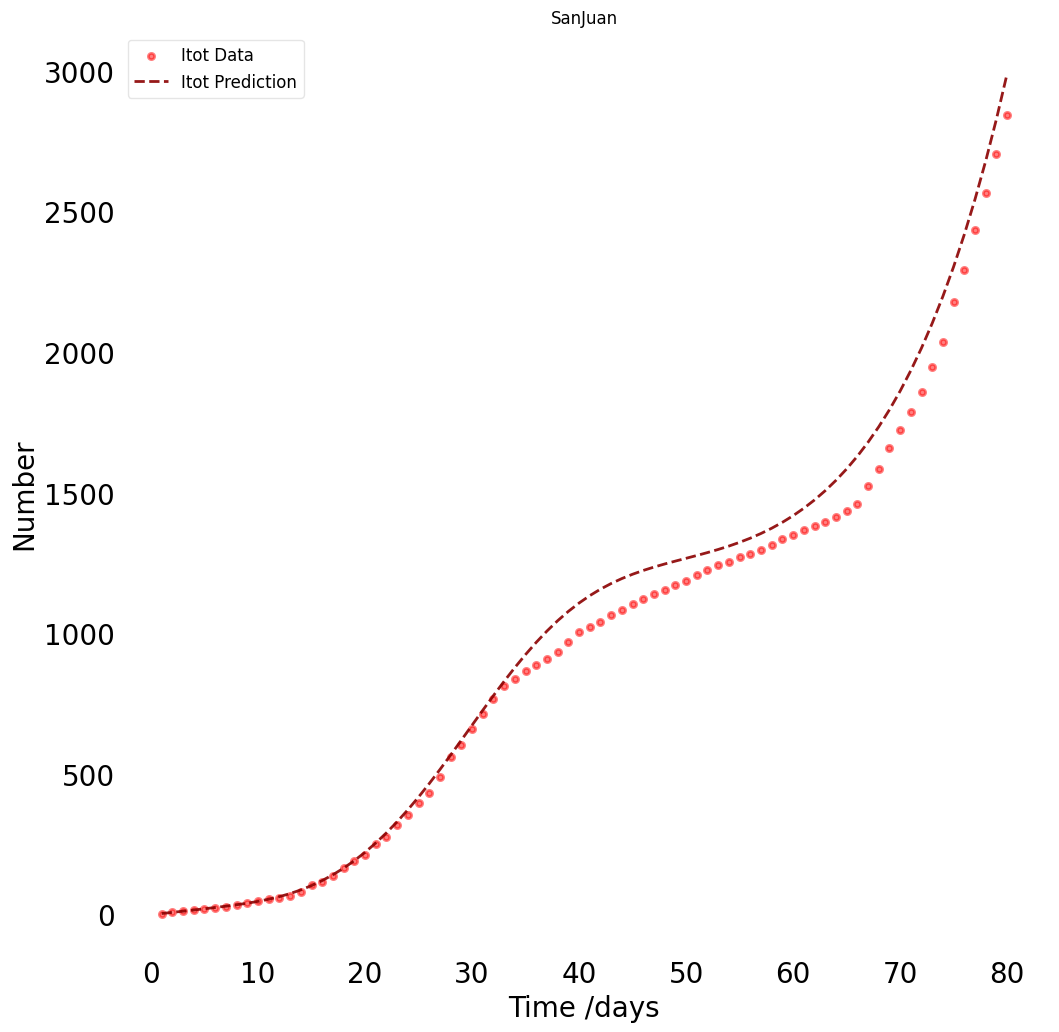

In [4]:
fig = plt.figure(figsize=(12,12))

ax = fig.add_subplot(111, facecolor='#dddddd', axisbelow=True)
ax.set_facecolor('xkcd:white')

# Only Itot has data - plot it with actual data points
ax.scatter(dengue_data[0], dengue_data[1], color = 'red', alpha=0.5, lw=2, label='Itot Data', s=20)
ax.plot(dengue_data[0], Itot_pred_list[0].detach().numpy(), 'darkred', alpha=0.9, lw=2, label='Itot Prediction', linestyle='dashed')

# # Plot predicted compartments (no data for these, only predictions from physics)
# ax.plot(dengue_data[0], Hr_pred_list[0].detach().numpy(), 'pink', alpha=0.7, lw=2, label='Hr Prediction', linestyle='dashed')
# ax.plot(dengue_data[0], Hs_pred_list[0].detach().numpy(), 'navy', alpha=0.7, lw=2, label='Hs Prediction', linestyle='dashed')
# ax.plot(dengue_data[0], He_pred_list[0].detach().numpy(), 'violet', alpha=0.7, lw=2, label='He Prediction', linestyle='dashed')
# ax.plot(dengue_data[0], Hi_pred_list[0].detach().numpy(), 'gold', alpha=0.7, lw=2, label='Hi Prediction', linestyle='dashed')
# ax.plot(dengue_data[0], Me_pred_list[0].detach().numpy(), 'teal', alpha=0.7, lw=2, label='Me Prediction', linestyle='dashed')
# ax.plot(dengue_data[0], Ms_pred_list[0].detach().numpy(), 'slategrey', alpha=0.7, lw=2, label='Ms Prediction', linestyle='dashed')
# ax.plot(dengue_data[0], Mi_pred_list[0].detach().numpy(), 'darkblue', alpha=0.7, lw=2, label='Mi Prediction', linestyle='dashed')

ax.set_xlabel('Time /days',size = 20)
ax.set_ylabel('Number',size = 20)
#ax.set_ylim([-1,50])
ax.yaxis.set_tick_params(length=0)
ax.xaxis.set_tick_params(length=0)
plt.xticks(size = 20)
plt.yticks(size = 20)
# ax.grid(b=True, which='major', c='black', lw=0.2, ls=20')
legend = ax.legend(prop={'size':12})
legend.get_frame().set_alpha(0.5)
for spine in ('top', 'right', 'bottom', 'left'):
    ax.spines[spine].set_visible(False)
plt.savefig('dengue.pdf')
plt.title('SanJuan')
plt.show()

In [5]:
# Calculate relative MSE loss for Itot (only available data)
import math

Itot_total_loss = 0 
Itot_den = 0

for timestep in range(len(dengue_data[0])):
    Itot_value = dengue_data[1][timestep] - Itot_pred_list[0][timestep].detach().numpy()
    Itot_total_loss += Itot_value**2
    Itot_den += (dengue_data[1][timestep])**2

Itot_total_loss = math.sqrt(Itot_total_loss/Itot_den)
print('Itot_total_loss (relative RMSE):', Itot_total_loss)

Itot_total_loss (relative RMSE): 0.07103584714683786
